# Mini-Projet Data Mining 2026/2027 — Étape 1 & 2 : EDA, Nettoyage & Tests Statistiques
**Auteurs (Codes Étudiants) :** RSD04 (Team Leader), CS12, CS22, CS29, IASD05, IASD25  
**Parcours :** Classification Supervisée  
**Sujet :** Prédiction de la satisfaction des passagers de compagnies aériennes (*Airline Passenger Satisfaction*)  
**Dataset :** Kaggle (*mysarahmadbhat*) — 129 880 lignes brutes (≥ 10 000 requis), 24 attributs (≥ 10 requis)

---
## 1. Objectifs de ce Notebook
1. Charger les données brutes et inspecter la volumétrie initiale (conformité ≥ 10 000 lignes et ≥ 10 attributs).
2. Analyser les types de données, les doublons et les valeurs manquantes (notamment `Arrival Delay`).
3. Explorer les distributions numériques et catégorielles, ainsi que les corrélations.
4. Réaliser au moins 4 tests statistiques scientifiquement justifiés avec hypothèses H0/H1, calcul de la p-value, taille d'effet et correction pour comparaisons multiples de Benjamini-Hochberg (FDR).


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuration de l'affichage
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

data_path = "../data/raw/airline_passenger_satisfaction.csv"
if not os.path.exists(data_path):
    data_path = "data/raw/airline_passenger_satisfaction.csv"

df_raw = pd.read_csv(data_path)
print(f"Dimensions brutes : {df_raw.shape[0]} lignes, {df_raw.shape[1]} attributs.")
assert df_raw.shape[0] >= 10000, "Erreur: Le dataset contient moins de 10 000 lignes brutes !"
assert df_raw.shape[1] >= 10, "Erreur: Le dataset contient moins de 10 attributs !"
print("-> Exigences de volumétrie du cahier des charges validées avec succès !")


Dimensions brutes : 129880 lignes, 24 attributs.
-> Exigences de volumétrie du cahier des charges validées avec succès !


## 2. Dictionnaire des Données et Aperçu Initial


In [2]:
df_raw.head()


,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied


In [3]:
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 24 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   ID                                      129880 non-null  int64  
 1   Gender                                  129880 non-null  str    
 2   Age                                     129880 non-null  int64  
 3   Customer Type                           129880 non-null  str    
 4   Type of Travel                          129880 non-null  str    
 5   Class                                   129880 non-null  str    
 6   Flight Distance                         129880 non-null  int64  
 7   Departure Delay                         129880 non-null  int64  
 8   Arrival Delay                           129487 non-null  float64
 9   Departure and Arrival Time Convenience  129880 non-null  int64  
 10  Ease of Online Booking                  129880 non-null

## 3. Analyse des Valeurs Manquantes et Doublons


In [4]:
# Recherche de doublons
n_duplicates = df_raw.duplicated().sum()
print(f"Nombre de lignes en double : {n_duplicates}")

# Analyse des valeurs manquantes
missing_series = df_raw.isnull().sum()
missing_pct = (missing_series / len(df_raw)) * 100
missing_df = pd.DataFrame({'Valeurs Manquantes': missing_series, 'Pourcentage (%)': missing_pct})
missing_df = missing_df[missing_df['Valeurs Manquantes'] > 0]
print(missing_df)


Nombre de lignes en double : 0
               Valeurs Manquantes  Pourcentage (%)
Arrival Delay                 393         0.302587


### Justification du traitement des valeurs manquantes
L'attribut `Arrival Delay` présente 393 valeurs manquantes (0.30% des données).  
Étant donné la forte asymétrie de la distribution des retards (médiane à 0 min, queue étalée vers la droite avec des retards allant jusqu'à plus de 1500 min), l'imputation par la **médiane** est scientifiquement préférable à la moyenne car elle est robuste aux valeurs extrêmes. Cette imputation est encapsulée dans le préprocesseur Scikit-Learn pour éviter toute fuite de données.


## 4. Nettoyage Initial : Suppression de l'identifiant ID


In [5]:
df = df_raw.drop(columns=['ID'], errors='ignore')
print(f"Nouvelle dimension après suppression de l'ID : {df.shape}")


Nouvelle dimension après suppression de l'ID : (129880, 23)


## 5. Analyse Exploratoire des Données (EDA)
### 5.1 Répartition de la Variable Cible `Satisfaction`


Répartition de la variable cible :
Satisfaction
Neutral or Dissatisfied    56.553742
Satisfied                  43.446258
Name: proportion, dtype: float64


C:\Users\PC\AppData\Local\Temp\ipykernel_15744\2536850473.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Satisfaction', palette=['#3182bd', '#e6550d'])


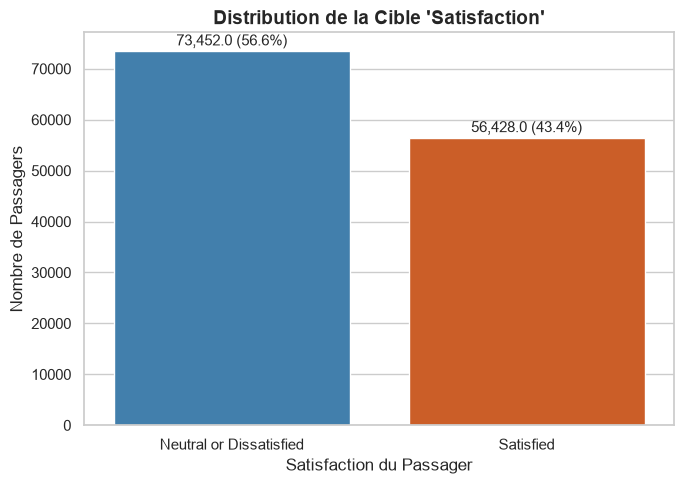

In [6]:
target_counts = df['Satisfaction'].value_counts(normalize=True) * 100
print("Répartition de la variable cible :")
print(target_counts)

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='Satisfaction', palette=['#3182bd', '#e6550d'])
plt.title("Distribution de la Cible 'Satisfaction'", fontsize=14, fontweight='bold')
plt.xlabel("Satisfaction du Passager", fontsize=12)
plt.ylabel("Nombre de Passagers", fontsize=12)
for p in ax.patches:
    ax.annotate(f"{p.get_height():,} ({p.get_height()/len(df)*100:.1f}%)",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 7), textcoords='offset points', fontsize=11)
plt.tight_layout()
plt.show()


### 5.2 Analyse des Variables Catégorielles vs Satisfaction


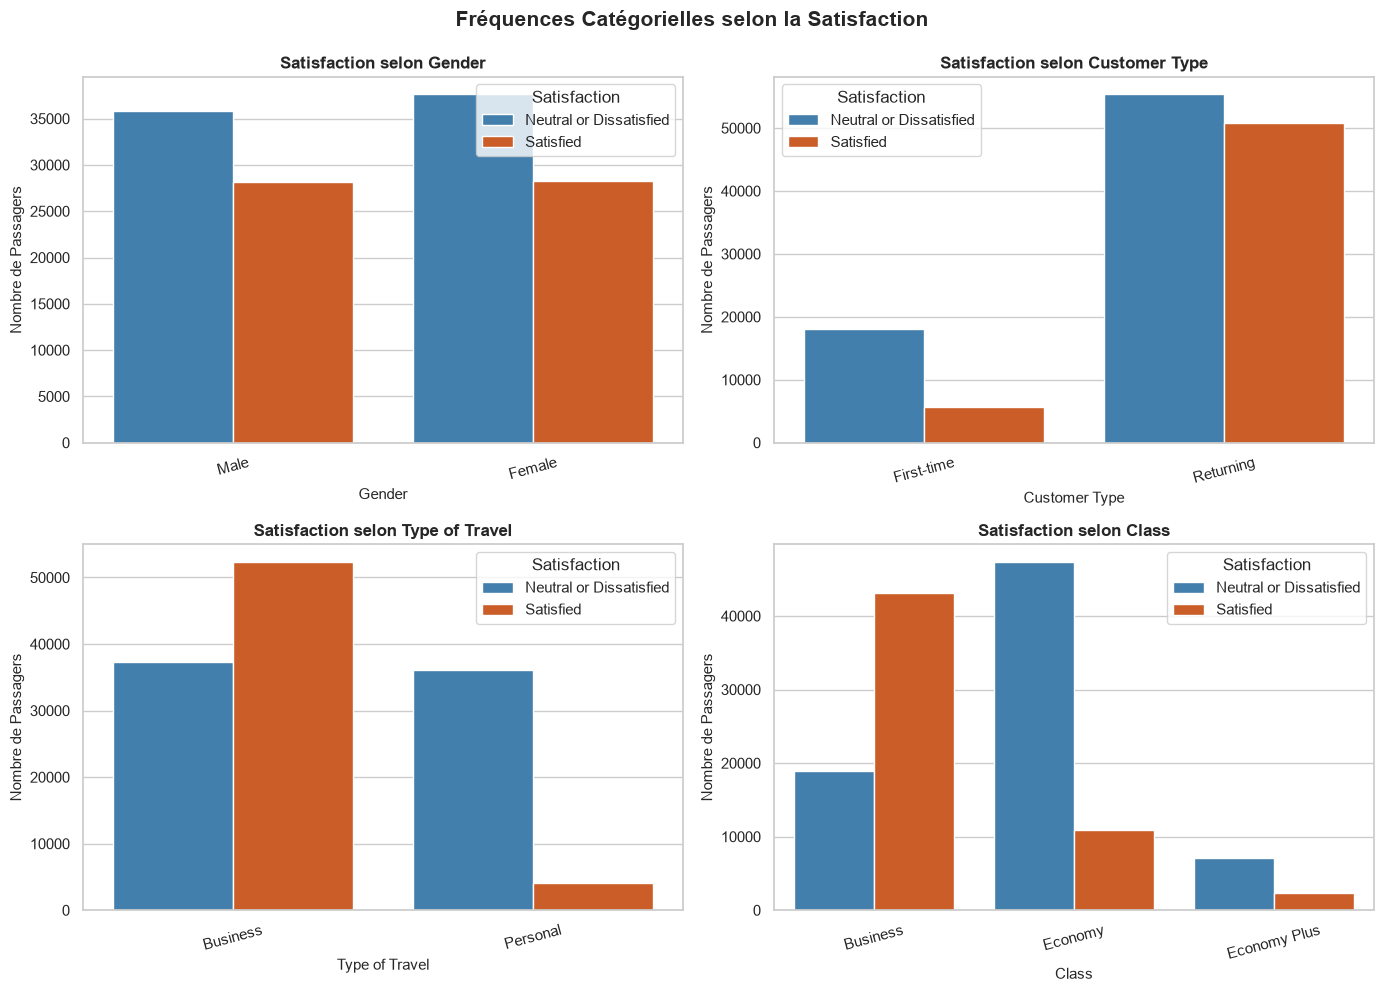

In [7]:
cat_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue='Satisfaction', ax=axes[idx], palette=['#3182bd', '#e6550d'])
    axes[idx].set_title(f"Satisfaction selon {col}", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel(col, fontsize=11)
    axes[idx].set_ylabel("Nombre de Passagers", fontsize=11)
    axes[idx].tick_params(axis='x', rotation=15)

plt.suptitle("Fréquences Catégorielles selon la Satisfaction", fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


### 5.3 Analyse des Variables Numériques Continues et Détection des Outliers (IQR)


In [8]:
num_continuous = ['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay']
df[num_continuous].describe().T


,count,mean,std,min,25%,50%,75%,max
Age,129880.0,39.427957,15.119360,7.0,27.0,40.0,51.0,85.0
Flight Distance,129880.0,1190.316392,997.452477,31.0,414.0,844.0,1744.0,4983.0
Departure Delay,129880.0,14.713713,38.071126,0.0,0.0,0.0,12.0,1592.0
Arrival Delay,129487.0,15.091129,38.465650,0.0,0.0,0.0,13.0,1584.0


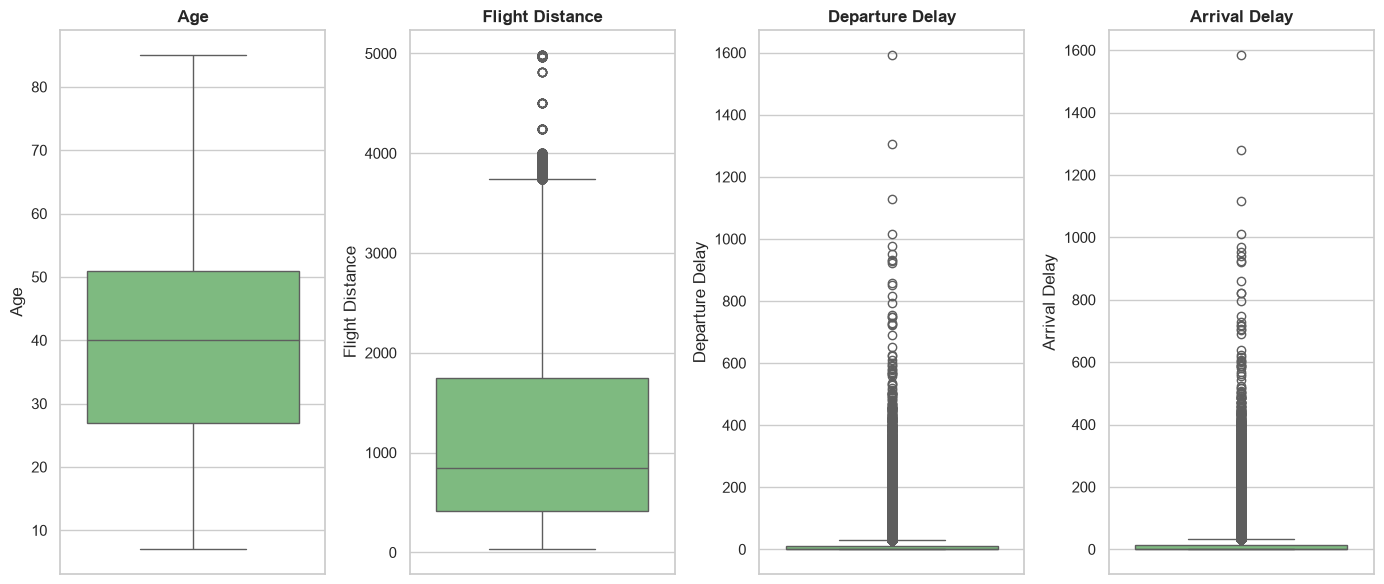

In [9]:
# Boxplots pour l'analyse des valeurs aberrantes (Outliers)
plt.figure(figsize=(14, 6))
for i, col in enumerate(num_continuous, 1):
    plt.subplot(1, 4, i)
    sns.boxplot(y=df[col], color='#74c476')
    plt.title(col, fontweight='bold')
plt.tight_layout()
plt.show()


### 5.4 Matrice de Corrélation Numérique


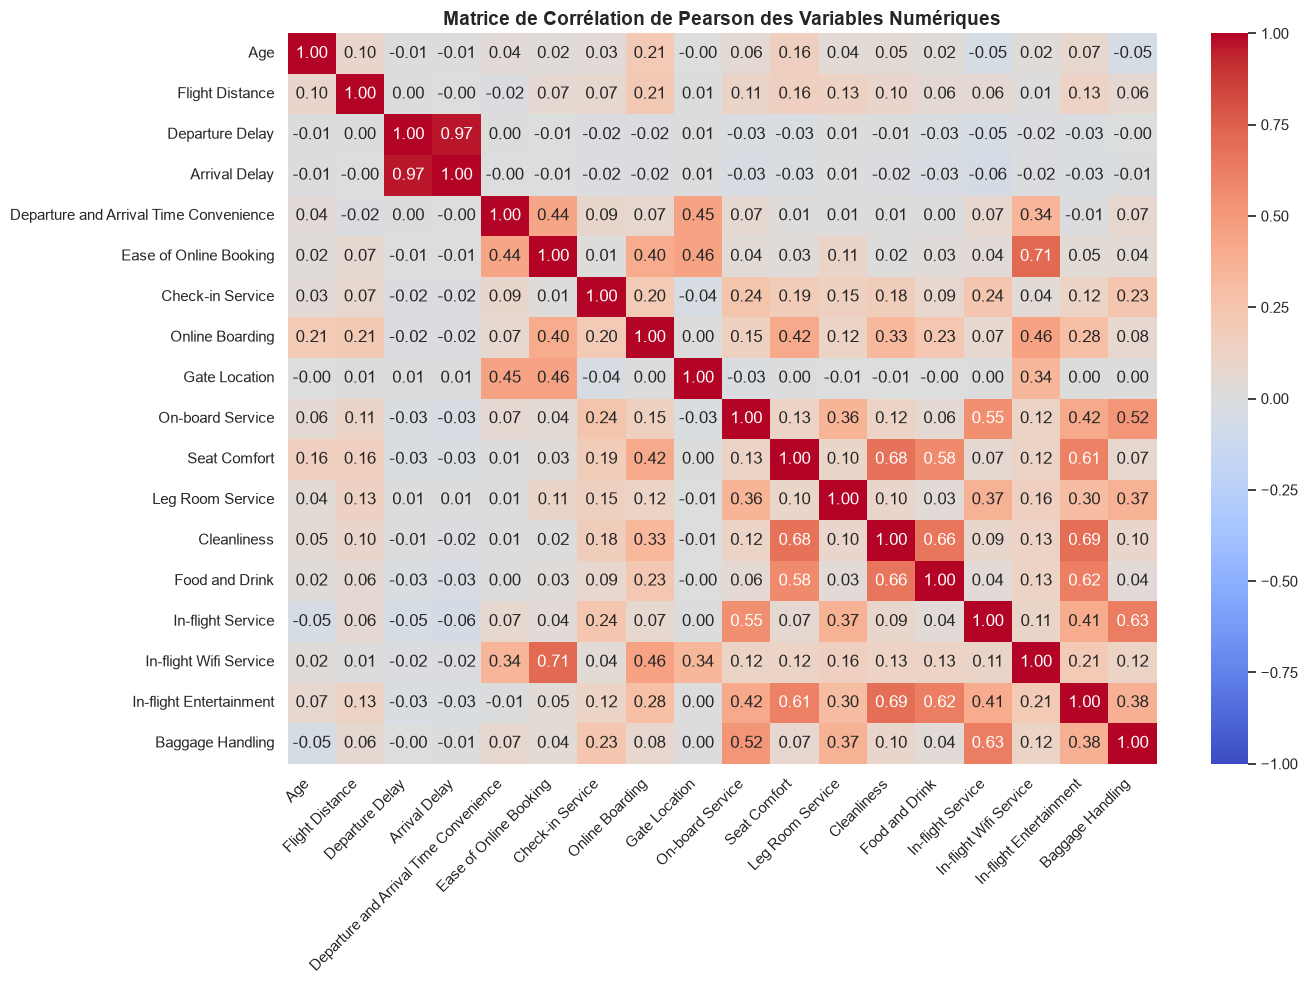

In [10]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(14, 10))
corr = df[numeric_cols].corr()
sns.heatmap(corr, cmap='coolwarm', annot=True, fmt='.2f', vmin=-1, vmax=1)
plt.title("Matrice de Corrélation de Pearson des Variables Numériques", fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 6. Tests Statistiques Approfondis avec Correction de Benjamini-Hochberg (FDR)
Le cahier des charges exige au minimum 2 tests statistiques scientifiquement appropriés et explicitement justifiés. Nous en implémentons 4 familles distinctes (26 tests unitaires au total) :
1. **Test de normalité (D'Agostino-Pearson omnibus)** : justifie le recours aux méthodes non paramétriques.
2. **Test de Mann-Whitney U** : compare les distributions continues entre satisfaits et non-satisfaits.
3. **Test du Chi² d'indépendance avec V de Cramér** : teste l'association entre variables qualitatives et satisfaction.
4. **Corrélation de rangs de Spearman** : évalue la monotonicité entre notes de service et satisfaction.
Toutes les p-values sont ajustées par la méthode de Benjamini-Hochberg (False Discovery Rate).


In [11]:
stat_results_path = "../data/processed/statistical_tests.json"
if not os.path.exists(stat_results_path):
    stat_results_path = "data/processed/statistical_tests.json"

if os.path.exists(stat_results_path):
    with open(stat_results_path, 'r', encoding='utf-8') as f:
        stat_results = json.load(f)
    stat_df = pd.DataFrame(stat_results)
    print(f"Total des tests statistiques chargés : {len(stat_df)}")
    display(stat_df[['test', 'variable', 'stat', 'p_raw', 'p_adj_BH', 'effect_size', 'significant_0.05']])
else:
    print("Le fichier statistical_tests.json sera généré par le pipeline complet.")


Total des tests statistiques chargés : 26


,test,variable,stat,p_raw,p_adj_BH,effect_size,significant_0.05
0,D'Agostino-Pearson Normalité,Age,6.032647e+03,0.000000e+00,0.000000e+00,"Skew=-0.00, Kurtosis=-0.72",True
1,D'Agostino-Pearson Normalité,Flight Distance,1.454671e+04,0.000000e+00,0.000000e+00,"Skew=1.11, Kurtosis=0.26",True
2,D'Agostino-Pearson Normalité,Departure Delay,1.323244e+05,0.000000e+00,0.000000e+00,"Skew=6.83, Kurtosis=99.57",True
3,D'Agostino-Pearson Normalité,Arrival Delay,1.302637e+05,0.000000e+00,0.000000e+00,"Skew=6.70, Kurtosis=94.96",True
4,Mann-Whitney U,Age vs Satisfaction,1.103056e+09,0.000000e+00,0.000000e+00,Rank-Biserial r=0.1683,True
5,Mann-Whitney U,Flight Distance vs Satisfaction,9.294665e+08,0.000000e+00,0.000000e+00,Rank-Biserial r=0.2992,True
6,Mann-Whitney U,Departure Delay vs Satisfaction,1.426617e+09,3.296593e-118,3.726583e-118,Rank-Biserial r=-0.0756,True
7,Mann-Whitney U,Arrival Delay vs Satisfaction,1.462314e+09,1.872835e-243,2.213351e-243,Rank-Biserial r=-0.1094,True
8,Chi² d'indépendance,Gender vs Satisfaction,1.215599e+01,4.893039e-04,5.088761e-04,V de Cramér=0.0108,True
9,Chi² d'indépendance,Customer Type vs Satisfaction,3.588032e+03,0.000000e+00,0.000000e+00,V de Cramér=0.1858,True
